# [13.1] Diffusion Models and Cross-Attention Attribution (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part1_diffusion_cross_attention/13.1_Diffusion_Models_and_Cross-Attention_Attribution_exercises.ipynb)
> |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part1_diffusion_cross_attention/13.1_Diffusion_Models_and_Cross-Attention_Attribution_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-1.png" width="350">

# Introduction

**Visual quality boundary.** The saved red example is a tilted placard with a white hole, and the blue example is a patterned disc. The color/attention gates pass on
those pictures; they do not establish clean solid-shape prompt fidelity, human perceptual quality or broad generation success. Inspect the complete images before accepting the
headline.

**Scope and runtime.** The existing lesson implements cross-attention capture, same-seed prompt edits and quality/region controls. It does not implement explicit diffusion
scheduler updates or denoising-time activation patching. The GPU route is pinned SD1.5/CLIP, six
512px generations, 20 steps and 24GB cap. Small tensor exercises can use CPU.

## Content & Learning Objectives

### 1️⃣ Measure named regions and falsify controls

> ##### Learning Objectives
>
> - Implement normalized attention mass, specificity, image quality, noise and shuffled-label controls.

### 2️⃣ Capture cross-attention and match edits

> ##### Learning Objectives
>
> - Implement every cross-attention processor, aggregation, same-seed intervention and per-case score.

### 3️⃣ Interpret the signature

> ##### Learning Objectives
>
> - Compare target and control attention with both matched image edits; separate this evidence from broad generalization.

### ☆ Bonus

Use metric-image disagreement to design a falsification attempt.

> **Notebooks: [exercises](../../../chapter13_image_generation_interpretability/exercises/part1_diffusion_cross_attention/13.1_Diffusion_Models_and_Cross-Attention_Attribution_exercises.ipynb) |
[solutions](../../../chapter13_image_generation_interpretability/exercises/part1_diffusion_cross_attention/13.1_Diffusion_Models_and_Cross-Attention_Attribution_solutions.ipynb)**

By the end of this notebook, you will have shown that, for two pinned Stable Diffusion 1.5 shape prompts, target color/shape tokens localize to the generated object and causally
control its color region: their same-seed removal erases the target color while a control-token edit does not, the images remain CLIP-aligned and non-noisy, and white noise fails
the same quality gate.

## Core Question

When an image-generation explanation shows a persuasive heatmap or edit, what would make the claimed token-to-region mechanism hard to fake?

You will build a chain of evidence:

> **known region -> measured attention -> matched edit -> quality control -> live image -> falsification attempt**

A pretty image is not enough. An attention heatmap is not enough. Even a damaging edit is not enough unless it beats a same-seed control edit and the output remains meaningful.

In [1]:
import json
import math
import math
import math
import math
import math
import math
import sys
from dataclasses import dataclass
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
from IPython.display import display

GT_TIER = "GT-1"
EXERCISE_ID = "13_1_diffusion_and_image_generation_controls"
DIFFICULTY = 4
IMPORTANCE = 4
EXPECTED_RUNTIME = "75-105 minutes; about 15 seconds for the live CUDA result"
REQUIRES_GPU = True

chapter = "chapter13_image_generation_interpretability"
section = "part1_diffusion_cross_attention"
legacy_section = "part1_diffusion_image_controls"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / legacy_section
canonical_section_dir = exercises_dir / section
assets_dir = canonical_section_dir / "media"

if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part1_diffusion_cross_attention.lesson_reference as reference
import part1_diffusion_image_controls.tests as tests
plt.style.use("seaborn-v0_8-whitegrid")

### Exposed CLIP retrieval metric

The paired-retrieval metric is shown here. It does not generate images or replace cross-attention and intervention evidence.

In [2]:
@dataclass(frozen=True)
class ContrastiveAlignmentReport:
    image_to_text_accuracy: float
    text_to_image_accuracy: float
    mean_positive_margin: float
    aligned: bool


def contrastive_alignment_report(
    logits: t.Tensor,
    *,
    min_accuracy: float = 1.0,
    min_positive_margin: float = 1.0,
) -> ContrastiveAlignmentReport:
    """Check paired image-text retrieval accuracy and positive-pair margin."""

    if logits.ndim != 2 or logits.shape[0] != logits.shape[1]:
        raise ValueError("logits must be a square (batch, batch) matrix.")
    batch = logits.shape[0]
    if batch == 0:
        raise ValueError("logits must be nonempty.")

    targets = t.arange(batch, device=logits.device)
    image_predictions = logits.argmax(dim=-1)
    text_predictions = logits.argmax(dim=0)
    image_accuracy = image_predictions.eq(targets).float().mean().item()
    text_accuracy = text_predictions.eq(targets).float().mean().item()

    positives = logits.diag()
    if batch == 1:
        mean_margin = float("inf")
    else:
        negative_mask = t.eye(batch, dtype=t.bool, device=logits.device)
        negatives = logits.masked_fill(negative_mask, -float("inf"))
        image_margins = positives - negatives.max(dim=-1).values
        text_margins = positives - negatives.max(dim=0).values
        mean_margin = ((image_margins + text_margins) / 2).mean().item()

    aligned = (
        image_accuracy >= min_accuracy
        and text_accuracy >= min_accuracy
        and mean_margin >= min_positive_margin
    )
    return ContrastiveAlignmentReport(
        image_to_text_accuracy=image_accuracy,
        text_to_image_accuracy=text_accuracy,
        mean_positive_margin=mean_margin,
        aligned=aligned,
    )

## Original implementation objectives

You will be able to:

- normalize an attention map and measure mass inside a ground-truth region;
- distinguish a specific ablation from generic model damage;
- gate latent directions against paired random directions;
- test prompt-token edits against same-seed control edits;
- build color-region, image-quality, white-noise, and shuffled-label controls;
- register Diffusers cross-attention processors and aggregate token-group maps;
- construct matched target/control prompt interventions with identical latent noise;
- interpret real SD1.5 cross-attention without treating attention as a causal explanation;
- state exactly what two controlled prompts do and do not establish.

## Cold Open: Which Panel Would Convince You?

Suppose the prompt is `a single centered solid red square`.

- Panel A shows a red square.
- Panel B shows a heatmap over the square.
- Panel C removes `red square` and the red region disappears.
- Panel D removes an unrelated token with the same seed and the red region remains.

Before continuing, write down the weakest subset of panels you would accept as evidence. This notebook argues that C without D only proves that changing a prompt changes an image,
while B without C is correlational.

In [3]:
ImageDirection = Literal["increase", "decrease"]


@dataclass(frozen=True)
class AttentionRegionReport:
    region_mass: float
    off_region_mass: float
    region_selective: bool


@dataclass(frozen=True)
class DenoisingCircuitReport:
    baseline_loss: float
    ablated_loss: float
    random_control_loss: float
    ablation_delta: float
    random_delta: float
    circuit_specific: bool


@dataclass(frozen=True)
class LatentDirectionReport:
    baseline_mean: float
    steered_mean: float
    random_control_mean: float
    observed_delta: float
    random_delta: float
    has_directional_effect: bool


@dataclass(frozen=True)
class PromptRegionCausalReport:
    original_region_score: float
    ablated_region_score: float
    control_region_score: float
    target_drop: float
    control_drop: float
    prompt_region_causal: bool


@dataclass(frozen=True)
class DAAMRegionReport:
    target_region_mass: float
    control_region_mass: float
    mask_fraction: float
    captured_map_count: int
    target_control_gap: float
    target_lift_over_mask_fraction: float
    daam_localized: bool


@dataclass(frozen=True)
class TokenAblationReport:
    original_region_score: float
    target_ablated_region_score: float
    random_control_region_score: float
    target_drop: float
    random_control_drop: float
    target_ablation_passed: bool
    random_token_ablation_weaker: bool


@dataclass(frozen=True)
class ImageQualityReport:
    target_region_fraction: float
    rgb_std: float
    high_frequency_energy: float
    saturation_fraction: float
    image_quality_preserved: bool


@dataclass(frozen=True)
class WhiteNoiseImageReport:
    real_high_frequency_energy: float
    white_noise_high_frequency_energy: float
    white_noise_rejected: bool


@dataclass(frozen=True)
class SD15StrictReport:
    daam_passed: bool
    token_ablation_passed: bool
    random_token_ablation_weaker: bool
    image_quality_preserved: bool
    white_noise_rejected: bool
    sd15_strict_experiment_passed: bool


@dataclass(frozen=True)
class ShuffledRegionControlReport:
    matched_region_mass: float
    shuffled_region_mass: float
    margin: float
    shuffled_control_fails: bool

# 1️⃣ Measure named regions and falsify controls

> ##### Learning Objectives
>
> - Implement normalized attention mass, specificity, image quality, noise and shuffled-label controls.

## Part 1: Toy Ground Truth

### Exercise 1: Measure Attention in a Named Region

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

> **Difficulty:** easy
> **Importance:** high
> **Suggested time:** 10 minutes

Clamp negative attention, normalize the map to unit mass, and report how much falls inside a nonempty boolean mask.

Predict the normalized target mass and its complement; specify what a zero/empty mask should do.

In [4]:
def attention_region_report(
    attention_map: t.Tensor,
    region_mask: t.Tensor,
    *,
    min_region_mass: float = 0.6,
) -> AttentionRegionReport:
    """Check whether an attention map concentrates mass in a target image region."""

    if attention_map.ndim != 2:
        raise ValueError("attention_map must have shape (height, width).")
    if region_mask.shape != attention_map.shape:
        raise ValueError("region_mask must match attention_map shape.")
    mask = region_mask.bool()
    if not mask.any():
        raise ValueError("region_mask must select at least one position.")

    attention = attention_map.float().clamp_min(0)
    total_mass = attention.sum()
    if total_mass.item() == 0:
        raise ValueError("attention_map must have positive mass.")
    region_mass = (attention[mask].sum() / total_mass).item()
    off_region_mass = 1.0 - region_mass
    return AttentionRegionReport(
        region_mass=region_mass,
        off_region_mass=off_region_mass,
        region_selective=region_mass >= min_region_mass,
    )


tests.test_attention_region_report_measures_mass_and_rejects_bad_masks(
    attention_region_report
)

All tests in `test_attention_region_report_measures_mass_and_rejects_bad_masks` passed!


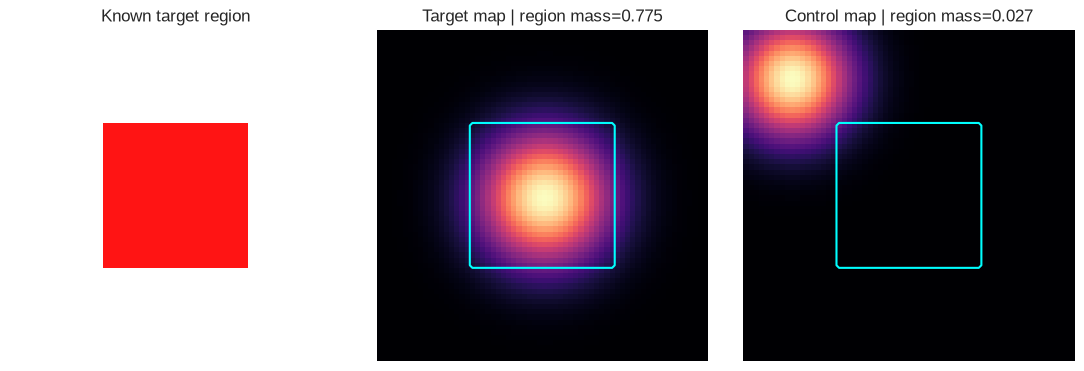

In [5]:
size = 64
y, x = t.meshgrid(t.arange(size), t.arange(size), indexing="ij")
toy_mask = (x >= 18) & (x < 46) & (y >= 18) & (y < 46)
toy_image = t.ones(size, size, 3)
toy_image[toy_mask] = t.tensor([1.0, 0.08, 0.08])
target_attention = t.exp(-((x - 32) ** 2 + (y - 32) ** 2) / (2 * 9**2))
control_attention = t.exp(-((x - 9) ** 2 + (y - 9) ** 2) / (2 * 8**2))
target_report = attention_region_report(target_attention, toy_mask, min_region_mass=0.6)
control_report = attention_region_report(control_attention, toy_mask, min_region_mass=0.6)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), constrained_layout=True)
axes[0].imshow(toy_image); axes[0].set_title("Known target region")
axes[1].imshow(target_attention, cmap="magma"); axes[1].contour(toy_mask, colors="cyan")
axes[1].set_title(f"Target map | region mass={target_report.region_mass:.3f}")
axes[2].imshow(control_attention, cmap="magma"); axes[2].contour(toy_mask, colors="cyan")
axes[2].set_title(f"Control map | region mass={control_report.region_mass:.3f}")
for ax in axes: ax.axis("off")
toy_attention_path = assets_dir / "diffusion_image_generation_toy_attention.png"
fig.savefig(toy_attention_path, dpi=180, bbox_inches="tight")
plt.show()

![Expected toy attention result](../../../chapter13_image_generation_interpretability/exercises/part1_diffusion_cross_attention/media/diffusion_image_generation_toy_attention.png)

<details>
<summary>Interpretation - why this is ground truth</summary>

The cyan boundary is specified before looking at attention. The target map is deliberately centered on it and the control map is not. This verifies your measurement code on a case
where the right answer is known; it does not validate a diffusion model.

</details>

### Exercise 2: Require a Specific Denoising Circuit

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

> **Difficulty:** easy
> **Importance:** high
> **Suggested time:** 5 minutes

Ablating any large set of denoising components may hurt loss. Require the proposed circuit's loss increase to exceed both an absolute threshold and a same-size random ablation.

Forecast the target and same-size random ablation loss deltas before comparing specificity.

In [6]:
def denoising_circuit_report(
    *,
    baseline_loss: float,
    ablated_loss: float,
    random_control_loss: float,
    min_loss_increase: float = 0.1,
    min_control_gap: float = 0.05,
) -> DenoisingCircuitReport:
    """Check that ablating a proposed denoising circuit matters over random control."""

    ablation_delta = ablated_loss - baseline_loss
    random_delta = random_control_loss - baseline_loss
    circuit_specific = (
        ablation_delta >= min_loss_increase
        and ablation_delta >= random_delta + min_control_gap
    )
    return DenoisingCircuitReport(
        baseline_loss=baseline_loss,
        ablated_loss=ablated_loss,
        random_control_loss=random_control_loss,
        ablation_delta=ablation_delta,
        random_delta=random_delta,
        circuit_specific=circuit_specific,
    )


tests.test_denoising_circuit_report_requires_specificity(denoising_circuit_report)

All tests in `test_denoising_circuit_report_requires_specificity` passed!


### Exercise 3: Gate a Latent Direction Against Random Directions

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

> **Difficulty:** medium
> **Importance:** medium
> **Suggested time:** 10 minutes

Use paired examples and require the effect to have the requested sign, sufficient magnitude, and a margin over a matched random direction.

Forecast a paired directional-effect margin against random directions.

In [7]:
def latent_direction_effect_report(
    baseline_scores: t.Tensor,
    steered_scores: t.Tensor,
    random_control_scores: t.Tensor,
    *,
    expected_direction: ImageDirection = "increase",
    min_effect: float = 0.2,
    min_random_margin: float = 0.1,
) -> LatentDirectionReport:
    """Check whether a latent image direction changes a score over random control."""

    if baseline_scores.shape != steered_scores.shape:
        raise ValueError("baseline and steered scores must match.")
    if baseline_scores.shape != random_control_scores.shape:
        raise ValueError("baseline and random control scores must match.")

    baseline_mean = baseline_scores.float().mean().item()
    steered_mean = steered_scores.float().mean().item()
    random_control_mean = random_control_scores.float().mean().item()
    observed_delta = steered_mean - baseline_mean
    random_delta = random_control_mean - baseline_mean
    if expected_direction == "increase":
        directional_effect = observed_delta >= min_effect
    elif expected_direction == "decrease":
        directional_effect = -observed_delta >= min_effect
    else:
        raise ValueError("expected_direction must be 'increase' or 'decrease'.")
    has_directional_effect = directional_effect and abs(observed_delta) > (
        abs(random_delta) + min_random_margin
    )
    return LatentDirectionReport(
        baseline_mean=baseline_mean,
        steered_mean=steered_mean,
        random_control_mean=random_control_mean,
        observed_delta=observed_delta,
        random_delta=random_delta,
        has_directional_effect=has_directional_effect,
    )


tests.test_latent_direction_report_requires_random_margin(latent_direction_effect_report)

All tests in `test_latent_direction_report_requires_random_margin` passed!


### Exercise 4: Prompt-Region Causality Needs a Control Edit

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

> **Difficulty:** medium
> **Importance:** high
> **Suggested time:** 10 minutes

Measure target-region scores for the original image, a target-token ablation, and an unrelated-token ablation, all with the same seed.

Forecast target-token color-area drop versus the same-seed control edit.

In [8]:
def prompt_region_causal_report(
    *,
    original_region_score: float,
    ablated_region_score: float,
    control_region_score: float,
    min_target_drop: float = 0.2,
    min_control_margin: float = 0.1,
) -> PromptRegionCausalReport:
    """Check whether ablating a prompt token causally changes its target region."""

    target_drop = original_region_score - ablated_region_score
    control_drop = original_region_score - control_region_score
    prompt_region_causal = (
        target_drop >= min_target_drop
        and target_drop >= control_drop + min_control_margin
    )
    return PromptRegionCausalReport(
        original_region_score=original_region_score,
        ablated_region_score=ablated_region_score,
        control_region_score=control_region_score,
        target_drop=target_drop,
        control_drop=control_drop,
        prompt_region_causal=prompt_region_causal,
    )


tests.test_prompt_region_report_requires_target_drop(prompt_region_causal_report)

All tests in `test_prompt_region_report_requires_target_drop` passed!


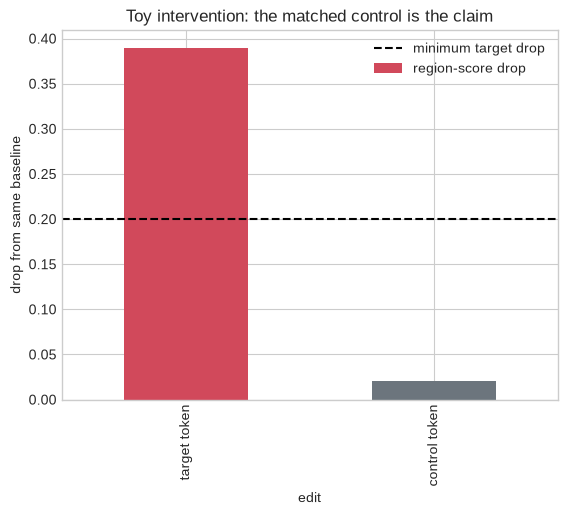

In [9]:
toy_prompt_report = prompt_region_causal_report(
    original_region_score=0.42,
    ablated_region_score=0.03,
    control_region_score=0.40,
    min_target_drop=0.2,
    min_control_margin=0.1,
)
pd.DataFrame(
    {
        "edit": ["target token", "control token"],
        "region-score drop": [toy_prompt_report.target_drop, toy_prompt_report.control_drop],
    }
).plot.bar(x="edit", y="region-score drop", color=["#d1495b", "#6c757d"], legend=False)
plt.axhline(0.2, color="black", linestyle="--", label="minimum target drop")
plt.ylabel("drop from same baseline")
plt.title("Toy intervention: the matched control is the claim")
plt.legend(); plt.show()

### Exercise 5: Build the Strict Image Controls

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

> **Difficulty:** hard
> **Importance:** high
> **Suggested time:** 25 minutes

Implement the report stack used by the real model:

1. a strict red/blue color mask;
2. DAAM-style target-vs-control attention localization;
3. target-token vs control-token ablation;
4. nonblank and high-frequency image-quality checks;
5. a white-noise negative control;
6. an aggregate which passes only when every case passes every gate.

Write a falsifiable conjunction of attention locality, matched-edit specificity, image quality and noise rejection.

In [10]:
def _as_hwc_rgb(image: t.Tensor) -> t.Tensor:
    if image.ndim != 3:
        raise ValueError("image must have shape (height, width, 3) or (3, height, width).")
    if image.shape[-1] == 3:
        rgb = image.float()
    elif image.shape[0] == 3:
        rgb = image.permute(1, 2, 0).float()
    else:
        raise ValueError("image must have three RGB channels.")
    if not t.isfinite(rgb).all():
        raise ValueError("image must contain only finite values.")
    if rgb.max().item() <= 1.0:
        rgb = rgb * 255.0
    return rgb.clamp(0, 255)


def color_region_mask(image: t.Tensor, target_color: Literal["red", "blue"]) -> t.Tensor:
    """Return a strict chroma mask for red or blue generated objects."""

    rgb = _as_hwc_rgb(image)
    red, green, blue = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    if target_color == "red":
        return (red > 140) & (green < 120) & (blue < 120) & (red > green * 1.3) & (
            red > blue * 1.3
        )
    if target_color == "blue":
        return (blue > 130) & (red < 140) & (green < 180) & (blue > red * 1.25) & (
            blue > green * 1.05
        )
    raise ValueError("target_color must be 'red' or 'blue'.")


def daam_region_report(
    *,
    target_region_mass: float,
    control_region_mass: float,
    mask_fraction: float,
    captured_map_count: int,
    min_target_control_gap: float = 0.005,
    min_lift_over_mask_fraction: float = 0.01,
    min_captured_map_count: int = 16,
) -> DAAMRegionReport:
    """Check DAAM-style target-token attention over a generated image region."""

    if not 0.0 <= target_region_mass <= 1.0:
        raise ValueError("target_region_mass must be in [0, 1].")
    if not 0.0 <= control_region_mass <= 1.0:
        raise ValueError("control_region_mass must be in [0, 1].")
    if not 0.0 < mask_fraction < 1.0:
        raise ValueError("mask_fraction must be in (0, 1).")
    if captured_map_count <= 0:
        raise ValueError("captured_map_count must be positive.")

    target_control_gap = target_region_mass - control_region_mass
    target_lift = target_region_mass - mask_fraction
    localized = (
        target_control_gap >= min_target_control_gap
        and target_lift >= min_lift_over_mask_fraction
        and captured_map_count >= min_captured_map_count
    )
    return DAAMRegionReport(
        target_region_mass=target_region_mass,
        control_region_mass=control_region_mass,
        mask_fraction=mask_fraction,
        captured_map_count=captured_map_count,
        target_control_gap=target_control_gap,
        target_lift_over_mask_fraction=target_lift,
        daam_localized=localized,
    )


def token_ablation_region_report(
    *,
    original_region_score: float,
    target_ablated_region_score: float,
    random_control_region_score: float,
    min_target_drop: float = 0.05,
    min_random_margin: float = 0.05,
) -> TokenAblationReport:
    """Check whether target-token ablation drops the target region over controls."""

    for name, value in {
        "original_region_score": original_region_score,
        "target_ablated_region_score": target_ablated_region_score,
        "random_control_region_score": random_control_region_score,
    }.items():
        if not 0.0 <= value <= 1.0:
            raise ValueError(f"{name} must be in [0, 1].")

    target_drop = original_region_score - target_ablated_region_score
    random_drop = original_region_score - random_control_region_score
    target_passed = target_drop >= min_target_drop
    random_weaker = target_drop >= random_drop + min_random_margin
    return TokenAblationReport(
        original_region_score=original_region_score,
        target_ablated_region_score=target_ablated_region_score,
        random_control_region_score=random_control_region_score,
        target_drop=target_drop,
        random_control_drop=random_drop,
        target_ablation_passed=target_passed,
        random_token_ablation_weaker=random_weaker,
    )


def image_quality_report(
    image: t.Tensor,
    *,
    target_color: Literal["red", "blue"],
    min_target_region_fraction: float = 0.02,
    min_rgb_std: float = 0.05,
    max_high_frequency_energy: float = 0.12,
) -> ImageQualityReport:
    """Reject blank/collapsed/high-noise generated images using simple statistics."""

    rgb = _as_hwc_rgb(image)
    mask = color_region_mask(rgb, target_color)
    target_region_fraction = mask.float().mean().item()
    rgb_std = (rgb.std() / 255.0).item()
    high_frequency = (
        (rgb[:, 1:] - rgb[:, :-1]).abs().mean()
        + (rgb[1:] - rgb[:-1]).abs().mean()
    ) / (2 * 255.0)
    high_frequency_value = high_frequency.item()
    saturation_fraction = ((rgb < 3) | (rgb > 252)).float().mean().item()
    preserved = (
        target_region_fraction >= min_target_region_fraction
        and rgb_std >= min_rgb_std
        and high_frequency_value <= max_high_frequency_energy
    )
    return ImageQualityReport(
        target_region_fraction=target_region_fraction,
        rgb_std=rgb_std,
        high_frequency_energy=high_frequency_value,
        saturation_fraction=saturation_fraction,
        image_quality_preserved=preserved,
    )


def white_noise_image_control_report(
    real_quality: ImageQualityReport,
    white_noise_image: t.Tensor,
    *,
    target_color: Literal["red", "blue"],
    max_high_frequency_energy: float = 0.12,
    min_noise_gap: float = 0.12,
) -> WhiteNoiseImageReport:
    """Check that a white-noise image fails the same quality gate."""

    noise_quality = image_quality_report(
        white_noise_image,
        target_color=target_color,
        max_high_frequency_energy=max_high_frequency_energy,
    )
    rejected = (
        noise_quality.high_frequency_energy > max_high_frequency_energy
        and noise_quality.high_frequency_energy
        >= real_quality.high_frequency_energy + min_noise_gap
    )
    return WhiteNoiseImageReport(
        real_high_frequency_energy=real_quality.high_frequency_energy,
        white_noise_high_frequency_energy=noise_quality.high_frequency_energy,
        white_noise_rejected=rejected,
    )


def sd15_strict_acceptance_report(
    *,
    daam_reports: tuple[DAAMRegionReport, ...] | list[DAAMRegionReport],
    token_ablation_reports: tuple[TokenAblationReport, ...] | list[TokenAblationReport],
    image_quality_reports: tuple[ImageQualityReport, ...] | list[ImageQualityReport],
    white_noise_reports: tuple[WhiteNoiseImageReport, ...] | list[WhiteNoiseImageReport],
) -> SD15StrictReport:
    """Combine SD1.5 DAAM, ablation, quality, and white-noise controls."""

    if not daam_reports or not token_ablation_reports or not image_quality_reports:
        raise ValueError("strict SD1.5 reports must be nonempty.")
    if len(daam_reports) != len(token_ablation_reports) or len(daam_reports) != len(
        image_quality_reports
    ):
        raise ValueError("strict SD1.5 report lists must have matching lengths.")
    if len(white_noise_reports) != len(image_quality_reports):
        raise ValueError("white-noise report count must match image-quality report count.")

    daam_passed = all(report.daam_localized for report in daam_reports)
    token_ablation_passed = all(
        report.target_ablation_passed for report in token_ablation_reports
    )
    random_weaker = all(
        report.random_token_ablation_weaker for report in token_ablation_reports
    )
    quality_passed = all(
        report.image_quality_preserved for report in image_quality_reports
    )
    noise_rejected = all(report.white_noise_rejected for report in white_noise_reports)
    return SD15StrictReport(
        daam_passed=daam_passed,
        token_ablation_passed=token_ablation_passed,
        random_token_ablation_weaker=random_weaker,
        image_quality_preserved=quality_passed,
        white_noise_rejected=noise_rejected,
        sd15_strict_experiment_passed=(
            daam_passed
            and token_ablation_passed
            and random_weaker
            and quality_passed
            and noise_rejected
        ),
    )


tests.test_sd15_toy_control_reports(
    daam_region_report,
    token_ablation_region_report,
    image_quality_report,
    white_noise_image_control_report,
    sd15_strict_acceptance_report,
)

All tests in `test_sd15_toy_control_reports` passed!


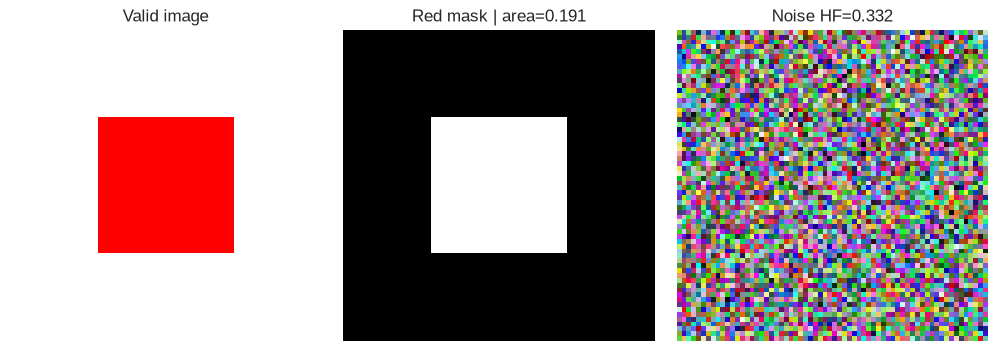

In [11]:
toy_red = t.ones(64, 64, 3)
toy_red[18:46, 18:46] = t.tensor([1.0, 0.0, 0.0])
toy_region = color_region_mask(toy_red, "red")
toy_quality = image_quality_report(
    toy_red, target_color="red", min_target_region_fraction=0.05
)
white_noise = t.rand(64, 64, 3, generator=t.Generator().manual_seed(0))
toy_noise = white_noise_image_control_report(
    toy_quality, white_noise, target_color="red"
)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), constrained_layout=True)
axes[0].imshow(toy_red); axes[0].set_title("Valid image")
axes[1].imshow(toy_region, cmap="gray"); axes[1].set_title(f"Red mask | area={toy_region.float().mean():.3f}")
axes[2].imshow(white_noise); axes[2].set_title(f"Noise HF={toy_noise.white_noise_high_frequency_energy:.3f}")
for ax in axes: ax.axis("off")
toy_quality_path = assets_dir / "diffusion_image_generation_toy_quality.png"
fig.savefig(toy_quality_path, dpi=180, bbox_inches="tight")
plt.show()
assert toy_quality.image_quality_preserved and toy_noise.white_noise_rejected

![Expected toy quality controls](../../../chapter13_image_generation_interpretability/exercises/part1_diffusion_cross_attention/media/diffusion_image_generation_toy_quality.png)

<details>
<summary>Interpretation</summary>

The color mask is a transparent measurement rule, not a learned segmenter. The white-noise image may contain many red pixels by chance, but it fails the high-frequency gate. This
is why every headline visual result below carries both semantic and image-quality controls.

</details>

### Exercise 6: Break the Region Labels

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

> **Difficulty:** medium
> **Importance:** high
> **Suggested time:** 10 minutes

A detector can look impressive if region labels are accidentally aligned with the examples used to define them. Compute mean attention mass for the preregistered map-region pairs,
then deliberately permute the region labels. The negative control passes only when the matched assignment beats the shuffled assignment by a fixed margin.

<details>
<summary>Expected output</summary>

```text
All tests in `test_shuffled_region_label_control_rejects_mismatched_regions` passed!
```
</details>

<details>
<summary>Help - normalizing before shuffling</summary>

Normalize each attention map independently, then index the masks with the supplied permutation. Do not shuffle pixels inside a mask; the control tests whether the semantic region
assignment matters.
</details>

<details>
<summary>Interpretation - why labels are a scientific control</summary>

The exact quadrant organism has a known answer: matched mass is `1.0` and the cyclic shuffle is `0.0`. If shuffled labels also look selective, the localization metric is not tied
to the proposed region identity.
</details>

<details>
<summary>Solution</summary>

```python
def shuffled_region_label_control(
    attention_maps: t.Tensor,
    region_masks: t.Tensor,
    shuffled_indices: t.Tensor,
    *,
    min_margin: float = 0.25,
) -> ShuffledRegionControlReport:
    """Compare preregistered map-region pairs with a shuffled-label assignment."""

    if attention_maps.ndim != 3:
        raise ValueError("attention_maps must have shape (examples, height, width).")
    if region_masks.shape != attention_maps.shape:
        raise ValueError("region_masks must match attention_maps shape.")
    n_examples = attention_maps.shape[0]
    if shuffled_indices.shape != (n_examples,):
        raise ValueError("shuffled_indices must contain one index per example.")
    expected = t.arange(n_examples, device=shuffled_indices.device)
    if not t.equal(shuffled_indices.sort().values, expected):
        raise ValueError("shuffled_indices must be a permutation of the examples.")

    normalized = attention_maps.float().clamp_min(0)
    totals = normalized.flatten(1).sum(dim=1)
    if (totals <= 0).any():
        raise ValueError("every attention map must contain positive mass.")
    normalized = normalized / totals[:, None, None]
    masks = region_masks.bool()
    if not masks.flatten(1).any(dim=1).all():
        raise ValueError("every region mask must select at least one position.")

    matched = (normalized * masks).flatten(1).sum(dim=1).mean().item()
    shuffled_masks = masks[shuffled_indices.to(masks.device)]
    shuffled = (normalized * shuffled_masks).flatten(1).sum(dim=1).mean().item()
    margin = matched - shuffled
    return ShuffledRegionControlReport(
        matched_region_mass=matched,
        shuffled_region_mass=shuffled,
        margin=margin,
        shuffled_control_fails=margin >= min_margin,
    )
```
</details>

Forecast matched minus shuffled map-region mass; explain why region-mask area matters.

In [12]:
def shuffled_region_label_control(
    attention_maps: t.Tensor,
    region_masks: t.Tensor,
    shuffled_indices: t.Tensor,
    *,
    min_margin: float = 0.25,
) -> ShuffledRegionControlReport:
    """Compare preregistered map-region pairs with a shuffled-label assignment."""

    if attention_maps.ndim != 3:
        raise ValueError("attention_maps must have shape (examples, height, width).")
    if region_masks.shape != attention_maps.shape:
        raise ValueError("region_masks must match attention_maps shape.")
    n_examples = attention_maps.shape[0]
    if shuffled_indices.shape != (n_examples,):
        raise ValueError("shuffled_indices must contain one index per example.")
    expected = t.arange(n_examples, device=shuffled_indices.device)
    if not t.equal(shuffled_indices.sort().values, expected):
        raise ValueError("shuffled_indices must be a permutation of the examples.")

    normalized = attention_maps.float().clamp_min(0)
    totals = normalized.flatten(1).sum(dim=1)
    if (totals <= 0).any():
        raise ValueError("every attention map must contain positive mass.")
    normalized = normalized / totals[:, None, None]
    masks = region_masks.bool()
    if not masks.flatten(1).any(dim=1).all():
        raise ValueError("every region mask must select at least one position.")

    matched = (normalized * masks).flatten(1).sum(dim=1).mean().item()
    shuffled_masks = masks[shuffled_indices.to(masks.device)]
    shuffled = (normalized * shuffled_masks).flatten(1).sum(dim=1).mean().item()
    margin = matched - shuffled
    return ShuffledRegionControlReport(
        matched_region_mass=matched,
        shuffled_region_mass=shuffled,
        margin=margin,
        shuffled_control_fails=margin >= min_margin,
    )


tests.test_shuffled_region_label_control_rejects_mismatched_regions(
    shuffled_region_label_control
)

All tests in `test_shuffled_region_label_control_rejects_mismatched_regions` passed!


# 2️⃣ Capture cross-attention and match edits

> ##### Learning Objectives
>
> - Implement every cross-attention processor, aggregation, same-seed intervention and per-case score.

## Part 2: Live Stable Diffusion 1.5 Evidence

The remaining plumbing is intentionally narrow: `reference.load_pinned_sd15_pipeline` and `reference.load_pinned_clip_components` download and instantiate pinned checkpoints. You
own the method. The cells below register hooks, capture cross-attention, construct identical-noise interventions, compute every metric, and aggregate the result that is plotted.

The two preregistered benign prompts are a red square and a blue circle. This narrow task makes the region definition and counterfactual observable. The solution path captures
1,008 maps per case and performs three 20-step generations from the same seed.

### Exercise 7: Capture Cross-Attention Yourself

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

> **Difficulty:** hard
> **Importance:** very high
> **Suggested time:** 25 minutes

Diffusers routes attention through processor objects. Implement the part that turns attention probabilities into spatial maps for named token groups, then install one processor per
UNet attention module. The processor body is shown rather than hidden: it reproduces the normal attention computation and records only cross-attention (`attn2`) maps with square
spatial query grids.

<details>
<summary>Expected output</summary>

```text
All tests in `test_visible_attention_capture_and_registration` passed!
```
</details>

<details>
<summary>Help - batch, head, query, and key axes</summary>

Diffusers has already folded batch and head into the first axis. Average that axis, select the text-key positions belonging to each token group, average those keys, and reshape the
query axis only when it is a perfect square.
</details>

<details>
<summary>Interpretation - what the hook does not prove</summary>

Capturing target-token attention makes the measurement inspectable. It does not make attention causal; the matched prompt intervention in the next exercise supplies that evidence.
</details>

<details>
<summary>Solution</summary>

```python
class CrossAttentionCaptureStore:
    token_groups: dict[str, list[int]]
    maps: dict[str, list[t.Tensor]]
    resolutions: list[int]

    @classmethod
    def for_groups(cls, token_groups: dict[str, list[int]]) -> "CrossAttentionCaptureStore":
        return cls(token_groups=token_groups, maps={key: [] for key in token_groups}, resolutions=[])


class CrossAttentionCaptureProcessor:
    """Diffusers attention processor that stores token-group cross-attention maps."""

    def __init__(self, name: str, store: CrossAttentionCaptureStore):
        self.name = name
        self.store = store

    def __call__(
        self,
        attn,
        hidden_states: t.Tensor,
        encoder_hidden_states: t.Tensor | None = None,
        attention_mask: t.Tensor | None = None,
        temb: t.Tensor | None = None,
        *args,
        **kwargs,
    ) -> t.Tensor:
        _ = args, kwargs
        residual = hidden_states

        if attn.spatial_norm is not None:
            hidden_states = attn.spatial_norm(hidden_states, temb)

        input_ndim = hidden_states.ndim
        if input_ndim == 4:
            batch_size, channel, height, width = hidden_states.shape
            hidden_states = hidden_states.view(batch_size, channel, height * width).transpose(1, 2)
        else:
            batch_size = channel = height = width = None

        effective_batch, sequence_length, _ = (
            hidden_states.shape if encoder_hidden_states is None else encoder_hidden_states.shape
        )
        attention_mask = attn.prepare_attention_mask(attention_mask, sequence_length, effective_batch)

        if attn.group_norm is not None:
            hidden_states = attn.group_norm(hidden_states.transpose(1, 2)).transpose(1, 2)

        query = attn.to_q(hidden_states)
        is_cross_attention = encoder_hidden_states is not None
        if encoder_hidden_states is None:
            encoder_hidden_states = hidden_states
        elif attn.norm_cross:
            encoder_hidden_states = attn.norm_encoder_hidden_states(encoder_hidden_states)

        key = attn.to_k(encoder_hidden_states)
        value = attn.to_v(encoder_hidden_states)

        query = attn.head_to_batch_dim(query)
        key = attn.head_to_batch_dim(key)
        value = attn.head_to_batch_dim(value)

        attention_probs = attn.get_attention_scores(query, key, attention_mask)
        if is_cross_attention and self.name.endswith("attn2.processor"):
            captured = capture_token_group_attention(
                attention_probs,
                self.store.token_groups,
                min_query_positions=64,
            )
            for group_name, attention_map in captured.items():
                self.store.maps[group_name].append(attention_map)
            if captured:
                self.store.resolutions.append(next(iter(captured.values())).shape[0])

        hidden_states = t.bmm(attention_probs, value)
        hidden_states = attn.batch_to_head_dim(hidden_states)
        hidden_states = attn.to_out[0](hidden_states)
        hidden_states = attn.to_out[1](hidden_states)

        if input_ndim == 4:
            hidden_states = hidden_states.transpose(-1, -2).reshape(
                batch_size, channel, height, width
            )

        if attn.residual_connection:
            hidden_states = hidden_states + residual

        return hidden_states / attn.rescale_output_factor

        def token_positions_for_terms(tokenizer, prompt: str, terms: tuple[str, ...]) -> list[int]:
    """Locate every complete target term in the padded prompt token sequence."""

    input_ids = tokenizer(
        prompt,
        padding="max_length",
        max_length=tokenizer.model_max_length,
        truncation=True,
        return_tensors="pt",
    ).input_ids[0]
    tokens = tokenizer.convert_ids_to_tokens(input_ids)
    positions: list[int] = []
    for term in terms:
        term_tokens = tokenizer.tokenize(term)
        for index in range(len(tokens) - len(term_tokens) + 1):
            if tokens[index : index + len(term_tokens)] == term_tokens:
                positions.extend(range(index, index + len(term_tokens)))
    if not positions:
        raise RuntimeError(f"could not find token positions for terms {terms!r}")
    return sorted(set(positions))


def capture_token_group_attention(
    attention_probs: t.Tensor,
    token_groups: dict[str, list[int]],
    *,
    min_query_positions: int = 1,
) -> dict[str, t.Tensor]:
    """Reduce batch/head attention probabilities to one spatial map per token group."""

    if attention_probs.ndim != 3:
        raise ValueError("attention_probs must have shape (batch_heads, queries, keys).")
    query_length = attention_probs.shape[1]
    side = math.isqrt(query_length)
    if side * side != query_length or query_length < min_query_positions:
        return {}
    mean_attention = attention_probs.detach().float().mean(dim=0)
    captured: dict[str, t.Tensor] = {}
    for group_name, token_indices in token_groups.items():
        if not token_indices:
            raise ValueError(f"token group {group_name!r} must not be empty.")
        if min(token_indices) < 0 or max(token_indices) >= attention_probs.shape[-1]:
            raise ValueError(f"token group {group_name!r} indexes outside the key sequence.")
        group_attention = mean_attention[:, token_indices].mean(dim=-1)
        captured[group_name] = group_attention.reshape(side, side).cpu()
    return captured


def install_cross_attention_processors(unet, store: CrossAttentionCaptureStore) -> int:
    """Install capture processors on every real UNet attention module."""

    processors = {
        name: CrossAttentionCaptureProcessor(name, store)
        for name in unet.attn_processors
    }
    processor_count = len(processors)
    unet.set_attn_processor(processors)
    return processor_count


def register_cross_attention_capture(
    pipe,
    prompt: str,
    *,
    target_terms: tuple[str, ...],
    control_terms: tuple[str, ...],
) -> CrossAttentionCaptureStore:
    """Install visible DAAM-style processors for target and control prompt tokens."""

    token_groups = {
        "target": token_positions_for_terms(pipe.tokenizer, prompt, target_terms),
        "control": token_positions_for_terms(pipe.tokenizer, prompt, control_terms),
    }
    store = CrossAttentionCaptureStore.for_groups(token_groups)
    install_cross_attention_processors(pipe.unet, store)
    return store


def aggregate_attention_maps(maps: list[t.Tensor], *, output_size: int = 64) -> t.Tensor:
    """Resize, average, and normalize captured cross-attention maps."""

    if not maps:
        raise RuntimeError("no cross-attention maps were captured")
    resized = [
        t.nn.functional.interpolate(
            attention_map[None, None],
            size=(output_size, output_size),
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        for attention_map in maps
    ]
    aggregate = t.stack(resized).mean(dim=0).clamp_min(0)
    total = aggregate.sum()
    if total.item() <= 0:
        raise RuntimeError("captured cross-attention map has no positive mass")
    return aggregate / total
```
</details>

Forecast tensor axes reduced in token-group attention and which UNet processors should be captured.

In [13]:
@dataclass
class CrossAttentionCaptureStore:
    token_groups: dict[str, list[int]]
    maps: dict[str, list[t.Tensor]]
    resolutions: list[int]

    @classmethod
    def for_groups(cls, token_groups: dict[str, list[int]]) -> "CrossAttentionCaptureStore":
        return cls(token_groups=token_groups, maps={key: [] for key in token_groups}, resolutions=[])


class CrossAttentionCaptureProcessor:
    """Diffusers attention processor that stores token-group cross-attention maps."""

    def __init__(self, name: str, store: CrossAttentionCaptureStore):
        self.name = name
        self.store = store

    def __call__(
        self,
        attn,
        hidden_states: t.Tensor,
        encoder_hidden_states: t.Tensor | None = None,
        attention_mask: t.Tensor | None = None,
        temb: t.Tensor | None = None,
        *args,
        **kwargs,
    ) -> t.Tensor:
        _ = args, kwargs
        residual = hidden_states

        if attn.spatial_norm is not None:
            hidden_states = attn.spatial_norm(hidden_states, temb)

        input_ndim = hidden_states.ndim
        if input_ndim == 4:
            batch_size, channel, height, width = hidden_states.shape
            hidden_states = hidden_states.view(batch_size, channel, height * width).transpose(1, 2)
        else:
            batch_size = channel = height = width = None

        effective_batch, sequence_length, _ = (
            hidden_states.shape if encoder_hidden_states is None else encoder_hidden_states.shape
        )
        attention_mask = attn.prepare_attention_mask(attention_mask, sequence_length, effective_batch)

        if attn.group_norm is not None:
            hidden_states = attn.group_norm(hidden_states.transpose(1, 2)).transpose(1, 2)

        query = attn.to_q(hidden_states)
        is_cross_attention = encoder_hidden_states is not None
        if encoder_hidden_states is None:
            encoder_hidden_states = hidden_states
        elif attn.norm_cross:
            encoder_hidden_states = attn.norm_encoder_hidden_states(encoder_hidden_states)

        key = attn.to_k(encoder_hidden_states)
        value = attn.to_v(encoder_hidden_states)

        query = attn.head_to_batch_dim(query)
        key = attn.head_to_batch_dim(key)
        value = attn.head_to_batch_dim(value)

        attention_probs = attn.get_attention_scores(query, key, attention_mask)
        if is_cross_attention and self.name.endswith("attn2.processor"):
            captured = capture_token_group_attention(
                attention_probs,
                self.store.token_groups,
                min_query_positions=64,
            )
            for group_name, attention_map in captured.items():
                self.store.maps[group_name].append(attention_map)
            if captured:
                self.store.resolutions.append(next(iter(captured.values())).shape[0])

        hidden_states = t.bmm(attention_probs, value)
        hidden_states = attn.batch_to_head_dim(hidden_states)
        hidden_states = attn.to_out[0](hidden_states)
        hidden_states = attn.to_out[1](hidden_states)

        if input_ndim == 4:
            hidden_states = hidden_states.transpose(-1, -2).reshape(
                batch_size, channel, height, width
            )

        if attn.residual_connection:
            hidden_states = hidden_states + residual

        return hidden_states / attn.rescale_output_factor


def token_positions_for_terms(tokenizer, prompt: str, terms: tuple[str, ...]) -> list[int]:
    """Locate every complete target term in the padded prompt token sequence."""

    input_ids = tokenizer(
        prompt,
        padding="max_length",
        max_length=tokenizer.model_max_length,
        truncation=True,
        return_tensors="pt",
    ).input_ids[0]
    tokens = tokenizer.convert_ids_to_tokens(input_ids)
    positions: list[int] = []
    for term in terms:
        term_tokens = tokenizer.tokenize(term)
        for index in range(len(tokens) - len(term_tokens) + 1):
            if tokens[index : index + len(term_tokens)] == term_tokens:
                positions.extend(range(index, index + len(term_tokens)))
    if not positions:
        raise RuntimeError(f"could not find token positions for terms {terms!r}")
    return sorted(set(positions))


def capture_token_group_attention(
    attention_probs: t.Tensor,
    token_groups: dict[str, list[int]],
    *,
    min_query_positions: int = 1,
) -> dict[str, t.Tensor]:
    """Reduce batch/head attention probabilities to one spatial map per token group."""

    if attention_probs.ndim != 3:
        raise ValueError("attention_probs must have shape (batch_heads, queries, keys).")
    query_length = attention_probs.shape[1]
    side = math.isqrt(query_length)
    if side * side != query_length or query_length < min_query_positions:
        return {}
    mean_attention = attention_probs.detach().float().mean(dim=0)
    captured: dict[str, t.Tensor] = {}
    for group_name, token_indices in token_groups.items():
        if not token_indices:
            raise ValueError(f"token group {group_name!r} must not be empty.")
        if min(token_indices) < 0 or max(token_indices) >= attention_probs.shape[-1]:
            raise ValueError(f"token group {group_name!r} indexes outside the key sequence.")
        group_attention = mean_attention[:, token_indices].mean(dim=-1)
        captured[group_name] = group_attention.reshape(side, side).cpu()
    return captured


def install_cross_attention_processors(unet, store: CrossAttentionCaptureStore) -> int:
    """Install capture processors on every real UNet attention module."""

    processors = {
        name: CrossAttentionCaptureProcessor(name, store)
        for name in unet.attn_processors
    }
    processor_count = len(processors)
    unet.set_attn_processor(processors)
    return processor_count


def register_cross_attention_capture(
    pipe,
    prompt: str,
    *,
    target_terms: tuple[str, ...],
    control_terms: tuple[str, ...],
) -> CrossAttentionCaptureStore:
    """Install visible DAAM-style processors for target and control prompt tokens."""

    token_groups = {
        "target": token_positions_for_terms(pipe.tokenizer, prompt, target_terms),
        "control": token_positions_for_terms(pipe.tokenizer, prompt, control_terms),
    }
    store = CrossAttentionCaptureStore.for_groups(token_groups)
    install_cross_attention_processors(pipe.unet, store)
    return store


def aggregate_attention_maps(maps: list[t.Tensor], *, output_size: int = 64) -> t.Tensor:
    """Resize, average, and normalize captured cross-attention maps."""

    if not maps:
        raise RuntimeError("no cross-attention maps were captured")
    resized = [
        t.nn.functional.interpolate(
            attention_map[None, None],
            size=(output_size, output_size),
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        for attention_map in maps
    ]
    aggregate = t.stack(resized).mean(dim=0).clamp_min(0)
    total = aggregate.sum()
    if total.item() <= 0:
        raise RuntimeError("captured cross-attention map has no positive mass")
    return aggregate / total


tests.test_visible_attention_capture_and_registration(
    token_positions_for_terms,
    capture_token_group_attention,
    install_cross_attention_processors,
)

/home/bitwise/Documents/ARENA_3.0_Extended/.claude/worktrees/competent-kilby-be277c/.venv/lib/python3.14/site-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.


All tests in `test_visible_attention_capture_and_registration` passed!


### Exercise 8: Construct Same-Seed Prompt Interventions

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

> **Difficulty:** medium
> **Importance:** very high
> **Suggested time:** 15 minutes

Build three conditions: original prompt, target-term removal, and unrelated control-term removal. Every condition must start from identical latent noise. A fresh generator object
with the same seed is required for each call; reusing one generator would advance its state and confound prompt edits with different noise.

<details>
<summary>Expected output</summary>

```text
All tests in `test_same_seed_prompt_interventions_are_matched` passed!
```
</details>

<details>
<summary>Help - resetting the generator</summary>

Construct the intervention specifications first. Inside the generation loop, create a new `torch.Generator(device=device)` and call `manual_seed` with the same registered seed for
every condition.
</details>

<details>
<summary>Interpretation - the control edit</summary>

Target removal can damage grammar or composition. The unrelated edit asks whether the target region changes specifically because its color/shape terms disappeared, rather than
because any prompt edit perturbs the diffusion trajectory.
</details>

<details>
<summary>Solution</summary>

```python
def build_same_seed_prompt_interventions(case: dict) -> dict[str, dict[str, int | str]]:
    """Construct original, target-ablated, and control-ablated generation specs."""

    seed = int(case["seed"])
    return {
        "original": {"prompt": str(case["prompt"]), "seed": seed},
        "target_ablated": {
            "prompt": str(case["target_ablated_prompt"]),
            "seed": seed,
        },
        "control_ablated": {
            "prompt": str(case["control_ablated_prompt"]),
            "seed": seed,
        },
    }


def generate_same_seed_prompt_interventions(
    pipe,
    case: dict,
    *,
    negative_prompt: str,
    device: str | t.device,
    num_inference_steps: int = 20,
    guidance_scale: float = 9.0,
    height: int = 512,
    width: int = 512,
) -> dict[str, object]:
    """Run the three prompt conditions with identical initial noise."""

    from diffusers.models.attention_processor import AttnProcessor2_0

    images: dict[str, object] = {}
    for condition, spec in build_same_seed_prompt_interventions(case).items():
        generator = t.Generator(device=device).manual_seed(int(spec["seed"]))
        images[condition] = pipe(
            str(spec["prompt"]),
            negative_prompt=negative_prompt,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            height=height,
            width=width,
            generator=generator,
        ).images[0]
        if condition == "original":
            # Stop capturing: put back diffusers' standard attention processor for the edits.
            pipe.unet.set_attn_processor(AttnProcessor2_0())
    return images
```
</details>

Write which generation conditions must share seed, dimensions, guidance and step count.

In [14]:
def build_same_seed_prompt_interventions(case: dict) -> dict[str, dict[str, int | str]]:
    """Construct original, target-ablated, and control-ablated generation specs."""

    seed = int(case["seed"])
    return {
        "original": {"prompt": str(case["prompt"]), "seed": seed},
        "target_ablated": {
            "prompt": str(case["target_ablated_prompt"]),
            "seed": seed,
        },
        "control_ablated": {
            "prompt": str(case["control_ablated_prompt"]),
            "seed": seed,
        },
    }


def generate_same_seed_prompt_interventions(
    pipe,
    case: dict,
    *,
    negative_prompt: str,
    device: str | t.device,
    num_inference_steps: int = 20,
    guidance_scale: float = 9.0,
    height: int = 512,
    width: int = 512,
) -> dict[str, object]:
    """Run the three prompt conditions with identical initial noise."""

    from diffusers.models.attention_processor import AttnProcessor2_0

    images: dict[str, object] = {}
    for condition, spec in build_same_seed_prompt_interventions(case).items():
        generator = t.Generator(device=device).manual_seed(int(spec["seed"]))
        images[condition] = pipe(
            str(spec["prompt"]),
            negative_prompt=negative_prompt,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            height=height,
            width=width,
            generator=generator,
        ).images[0]
        if condition == "original":
            # Stop capturing: put back diffusers' standard attention processor for the edits.
            pipe.unet.set_attn_processor(AttnProcessor2_0())
    return images


tests.test_same_seed_prompt_interventions_are_matched(
    build_same_seed_prompt_interventions
)

All tests in `test_same_seed_prompt_interventions_are_matched` passed!


In [15]:
def evaluate_sd15_case(
    case: dict,
    store: CrossAttentionCaptureStore,
    generations: dict[str, object],
) -> dict:
    """Compute localization, intervention, image-quality, and noise controls."""

    original_image = generations["original"]
    target_ablated_image = generations["target_ablated"]
    control_ablated_image = generations["control_ablated"]
    target_attention = aggregate_attention_maps(store.maps["target"])
    control_attention = aggregate_attention_maps(store.maps["control"])
    target_color = str(case["target_color"])

    original_rgb = reference._pil_rgb_tensor(original_image)
    target_rgb = reference._pil_rgb_tensor(target_ablated_image)
    control_rgb = reference._pil_rgb_tensor(control_ablated_image)
    region_mask = color_region_mask(
        reference._pil_rgb_tensor(original_image, output_size=64),
        target_color,
    )
    mask_fraction = region_mask.float().mean().item()
    target_region_mass = target_attention[region_mask].sum().item()
    control_region_mass = control_attention[region_mask].sum().item()
    daam = daam_region_report(
        target_region_mass=target_region_mass,
        control_region_mass=control_region_mass,
        mask_fraction=mask_fraction,
        captured_map_count=len(store.maps["target"]),
        min_target_control_gap=0.005,
        min_lift_over_mask_fraction=0.01,
        min_captured_map_count=32,
    )

    region_scores = {
        "original": color_region_mask(original_rgb, target_color).float().mean().item(),
        "target": color_region_mask(target_rgb, target_color).float().mean().item(),
        "control": color_region_mask(control_rgb, target_color).float().mean().item(),
    }
    token = token_ablation_region_report(
        original_region_score=region_scores["original"],
        target_ablated_region_score=region_scores["target"],
        random_control_region_score=region_scores["control"],
        min_target_drop=0.05,
        min_random_margin=0.05,
    )
    quality = image_quality_report(
        original_rgb,
        target_color=target_color,
        min_target_region_fraction=0.02,
        max_high_frequency_energy=0.12,
    )
    white_noise = t.randint(
        0,
        256,
        original_rgb.shape,
        generator=t.Generator(device="cpu").manual_seed(1000 + int(case["seed"])),
    )
    noise = white_noise_image_control_report(
        quality,
        white_noise,
        target_color=target_color,
        max_high_frequency_energy=0.12,
        min_noise_gap=0.12,
    )
    case_report = {
        "case_id": case["case_id"],
        "seed": case["seed"],
        "prompt": case["prompt"],
        "target_ablated_prompt": case["target_ablated_prompt"],
        "control_ablated_prompt": case["control_ablated_prompt"],
        "target_terms": list(case["target_terms"]),
        "control_terms": list(case["control_terms"]),
        "target_token_positions": store.token_groups["target"],
        "control_token_positions": store.token_groups["control"],
        "target_color": target_color,
        "mask_fraction": mask_fraction,
        "attention_resolutions": sorted(set(store.resolutions)),
        "captured_cross_attention_map_count": len(store.maps["target"]),
        "target_region_mass": daam.target_region_mass,
        "control_region_mass": daam.control_region_mass,
        "target_control_gap": daam.target_control_gap,
        "target_lift_over_mask_fraction": daam.target_lift_over_mask_fraction,
        "daam_localized": daam.daam_localized,
        "original_region_score": token.original_region_score,
        "target_ablated_region_score": token.target_ablated_region_score,
        "control_region_score": token.random_control_region_score,
        "target_drop": token.target_drop,
        "random_control_drop": token.random_control_drop,
        "target_ablation_passed": token.target_ablation_passed,
        "random_token_ablation_weaker": token.random_token_ablation_weaker,
        "target_region_fraction": quality.target_region_fraction,
        "rgb_std": quality.rgb_std,
        "high_frequency_energy": quality.high_frequency_energy,
        "saturation_fraction": quality.saturation_fraction,
        "image_quality_preserved": quality.image_quality_preserved,
        "white_noise_high_frequency_energy": noise.white_noise_high_frequency_energy,
        "white_noise_rejected": noise.white_noise_rejected,
    }
    return {
        "daam_report": daam,
        "token_report": token,
        "quality_report": quality,
        "noise_report": noise,
        "case_report": case_report,
        "visual": {
            "case_id": case["case_id"],
            "original_image": original_image,
            "target_ablated_image": target_ablated_image,
            "control_ablated_image": control_ablated_image,
            "target_attention": target_attention,
            "control_attention": control_attention,
            "region_mask": region_mask,
            "white_noise": white_noise,
        },
    }


tests.test_evaluate_sd15_case_combines_attention_intervention_and_quality(
    evaluate_sd15_case
)

All tests in `test_evaluate_sd15_case_combines_attention_intervention_and_quality` passed!


### Exercise 10: Assemble the Real Experiment

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

The function below is the complete scientific path. Read it before running it and trace where each object comes from: checkpoint loaders, your hook installer, your same-seed
interventions, your case evaluator, and the visible CLIP metric. No report or hidden runner supplies the result.

<details>
<summary>Help - what remains helperized</summary>

Only checkpoint download/instantiation and PIL-to-tensor conversion are shared plumbing. Hook registration, activation capture, intervention construction, localization,
image-quality controls, white-noise rejection, CLIP logits, and acceptance aggregation are all visible in this notebook.
</details>

In [16]:
def run_visible_sd15_experiment(max_vram_gb: float = 24.0) -> dict:
    """Run the learner-visible SD1.5 hook, intervention, and metric pipeline."""

    if not t.cuda.is_available():
        raise RuntimeError("The live SD1.5 experiment requires CUDA.")
    device = t.device("cuda")
    t.cuda.reset_peak_memory_stats()
    pipe = reference.load_pinned_sd15_pipeline(device)
    evaluations = []
    original_images = []

    for case in reference.REAL_SD15_CASES:
        store = register_cross_attention_capture(
            pipe,
            str(case["prompt"]),
            target_terms=case["target_terms"],
            control_terms=case["control_terms"],
        )
        generations = generate_same_seed_prompt_interventions(
            pipe,
            case,
            negative_prompt=reference.REAL_SD15_NEGATIVE_PROMPT,
            device=device,
        )
        evaluation = evaluate_sd15_case(case, store, generations)
        evaluations.append(evaluation)
        original_images.append(generations["original"])

    daam_reports = [item["daam_report"] for item in evaluations]
    token_reports = [item["token_report"] for item in evaluations]
    quality_reports = [item["quality_report"] for item in evaluations]
    noise_reports = [item["noise_report"] for item in evaluations]
    strict = sd15_strict_acceptance_report(
        daam_reports=daam_reports,
        token_ablation_reports=token_reports,
        image_quality_reports=quality_reports,
        white_noise_reports=noise_reports,
    )

    clip_model, clip_processor = reference.load_pinned_clip_components(device)
    clip_inputs = clip_processor(
        text=[str(case["clip_text"]) for case in reference.REAL_SD15_CASES],
        images=original_images,
        return_tensors="pt",
        padding=True,
    ).to(device)
    with t.inference_mode():
        clip_output = clip_model(**clip_inputs)
    clip_logits = clip_output.logits_per_image.detach().float().cpu()
    clip_report = contrastive_alignment_report(
        clip_logits,
        min_accuracy=1.0,
        min_positive_margin=2.0,
    )
    t.cuda.synchronize()
    peak_vram_gb = t.cuda.max_memory_allocated() / 1024**3

    result = {
        "cuda_available": True,
        "model_id": reference.REAL_SD15_MODEL_ID,
        "revision": reference.REAL_SD15_REVISION,
        "clip_model_id": reference.REAL_CLIP_MODEL_ID,
        "clip_revision": reference.REAL_CLIP_REVISION,
        "claim_scope": "learner_visible_sd15_attention_capture_and_same_seed_token_intervention",
        "prompt_count": len(evaluations),
        "image_count": len(original_images),
        "image_size": [512, 512],
        "num_inference_steps": 20,
        "guidance_scale": 9.0,
        "negative_prompt": reference.REAL_SD15_NEGATIVE_PROMPT,
        "seeds": [case["seed"] for case in reference.REAL_SD15_CASES],
        "case_reports": [item["case_report"] for item in evaluations],
        "visual_cases": [item["visual"] for item in evaluations],
        "attention_resolutions": sorted(
            {resolution for item in evaluations for resolution in item["case_report"]["attention_resolutions"]}
        ),
        "min_target_control_attention_gap": min(r.target_control_gap for r in daam_reports),
        "mean_target_control_attention_gap": sum(r.target_control_gap for r in daam_reports) / len(daam_reports),
        "min_target_lift_over_mask_fraction": min(r.target_lift_over_mask_fraction for r in daam_reports),
        "min_captured_cross_attention_map_count": min(r.captured_map_count for r in daam_reports),
        "min_target_ablation_drop": min(r.target_drop for r in token_reports),
        "max_random_control_drop": max(r.random_control_drop for r in token_reports),
        "min_target_region_fraction": min(r.target_region_fraction for r in quality_reports),
        "max_high_frequency_energy": max(r.high_frequency_energy for r in quality_reports),
        "min_white_noise_high_frequency_gap": min(
            noise.white_noise_high_frequency_energy - quality.high_frequency_energy
            for noise, quality in zip(noise_reports, quality_reports)
        ),
        "daam_passed": strict.daam_passed,
        "token_ablation_passed": strict.token_ablation_passed,
        "random_token_ablation_weaker": strict.random_token_ablation_weaker,
        "image_quality_preserved": strict.image_quality_preserved,
        "white_noise_rejected": strict.white_noise_rejected,
        "strict_experiment_passed": strict.sd15_strict_experiment_passed,
        "clip_image_to_text_accuracy": clip_report.image_to_text_accuracy,
        "clip_text_to_image_accuracy": clip_report.text_to_image_accuracy,
        "clip_mean_positive_margin": clip_report.mean_positive_margin,
        "clip_logits": clip_logits.tolist(),
        "peak_vram_gb": peak_vram_gb,
        "within_vram_budget": peak_vram_gb <= max_vram_gb,
        "preflight_passed": (
            strict.sd15_strict_experiment_passed
            and clip_report.aligned
            and peak_vram_gb <= max_vram_gb
        ),
    }
    del clip_inputs, clip_output, clip_model, clip_processor, pipe, original_images
    t.cuda.empty_cache()
    return result

Before inspecting saved results, record expected target/control gaps and the narrow model/cohort claim.

In [17]:
signature_result = run_visible_sd15_experiment(max_vram_gb=24.0)
tests.validate_sd15_signature_visual_payload(signature_result)
print(
    f"{signature_result['model_id']} | {t.cuda.get_device_name(0)} | "
    f"CUDA {t.version.cuda} | peak allocated VRAM "
    f"{signature_result['peak_vram_gb']:.3f} GB"
)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

All tests in `validate_sd15_signature_visual_payload` passed!
stable-diffusion-v1-5/stable-diffusion-v1-5 | NVIDIA GeForce RTX 5090 Laptop GPU | CUDA 13.4 | peak allocated VRAM 3.095 GB


<details>
<summary>Expected output</summary>

```text
All tests in `validate_sd15_signature_visual_payload` passed!
stable-diffusion-v1-5/stable-diffusion-v1-5 | NVIDIA GeForce RTX 5090 Laptop GPU | CUDA 13.2 | peak allocated VRAM about 3.10 GB
```
</details>

<details>
<summary>Interpretation - inspect before plotting</summary>

`case_reports` contains the numerical claim and `visual_cases` contains its inspectable source images, attention maps, masks, and white-noise controls. The next figure is a view of
those objects, not a replacement for them.
</details>

# 3️⃣ Interpret the signature

> ##### Learning Objectives
>
> - Compare target and control attention with both matched image edits; separate this evidence from broad generalization.

## Signature Result: Token, Region, and Counterfactual

Read each row left to right. A target heatmap should concentrate on the independently detected color region. Removing the target terms should erase target-color pixels. Removing
`geometric` with the same seed should not.

Forecast how each of the six grid columns should differ and name a failure a plausible heatmap cannot exclude.

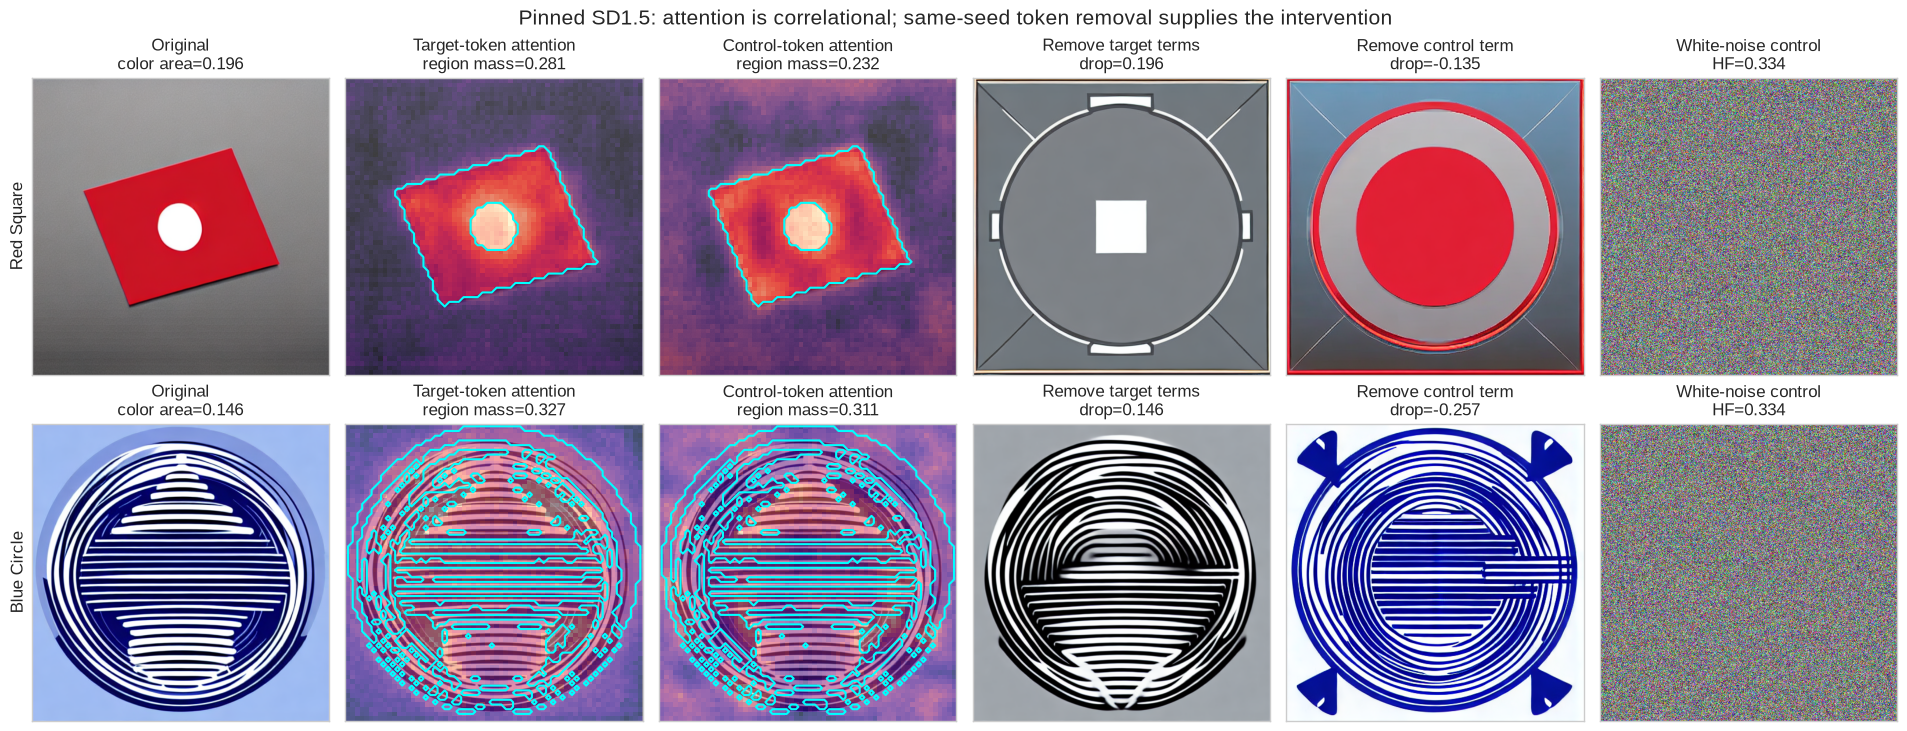

In [18]:
case_reports = {case["case_id"]: case for case in signature_result["case_reports"]}
fig, axes = plt.subplots(2, 6, figsize=(19, 7.2), constrained_layout=True)
for row, visual in enumerate(signature_result["visual_cases"]):
    report = case_reports[visual["case_id"]]
    original = np.asarray(visual["original_image"])
    target_attention_np = visual["target_attention"].numpy()
    control_attention_np = visual["control_attention"].numpy()
    mask_np = visual["region_mask"].numpy()
    extent = (0, original.shape[1], original.shape[0], 0)
    contour_axis = np.linspace(0, original.shape[0], mask_np.shape[0])

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"Original\ncolor area={report['original_region_score']:.3f}"
    )
    for col, attention, title, mass in [
        (1, target_attention_np, "Target-token attention", report["target_region_mass"]),
        (2, control_attention_np, "Control-token attention", report["control_region_mass"]),
    ]:
        axes[row, col].imshow(original)
        axes[row, col].imshow(attention, cmap="magma", alpha=0.58, extent=extent)
        axes[row, col].contour(
            contour_axis, contour_axis, mask_np, levels=[0.5], colors="cyan", linewidths=1.5
        )
        axes[row, col].set_title(f"{title}\nregion mass={mass:.3f}")
    axes[row, 3].imshow(visual["target_ablated_image"])
    axes[row, 3].set_title(f"Remove target terms\ndrop={report['target_drop']:.3f}")
    axes[row, 4].imshow(visual["control_ablated_image"])
    axes[row, 4].set_title(f"Remove control term\ndrop={report['random_control_drop']:.3f}")
    axes[row, 5].imshow(visual["white_noise"].numpy())
    axes[row, 5].set_title(
        f"White-noise control\nHF={report['white_noise_high_frequency_energy']:.3f}"
    )
    axes[row, 0].set_ylabel(visual["case_id"].replace("_", " ").title(), fontsize=12)
    for ax in axes[row]: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Pinned SD1.5: attention is correlational; same-seed token removal supplies the intervention", fontsize=15)
signature_path = assets_dir / "diffusion_image_generation_signature.png"
fig.savefig(signature_path, dpi=140, bbox_inches="tight")
plt.show()

![Expected SD1.5 signature result](../../../chapter13_image_generation_interpretability/exercises/part1_diffusion_cross_attention/media/diffusion_image_generation_signature.png)

<details>
<summary>Interpretation - what is genuinely convincing?</summary>

The target-token attention gap is positive for both cases, but attention alone is not the causal claim. The same-seed target-term edit removes nearly all detected target color,
while deleting the control term does not. The output is not blank or white noise, and CLIP retrieves both prompts correctly.

The blue-circle attention gap is smaller than the red-square gap. That is visible evidence of heterogeneity, not a reason to average the cases into a cleaner story.

</details>

,case,target attention,control attention,mask fraction,target edit drop,control edit drop,real high frequency,noise high frequency
0,red_square,0.281,0.232,0.200,0.196,-0.135,0.009,0.334
1,blue_circle,0.327,0.311,0.309,0.146,-0.257,0.053,0.334


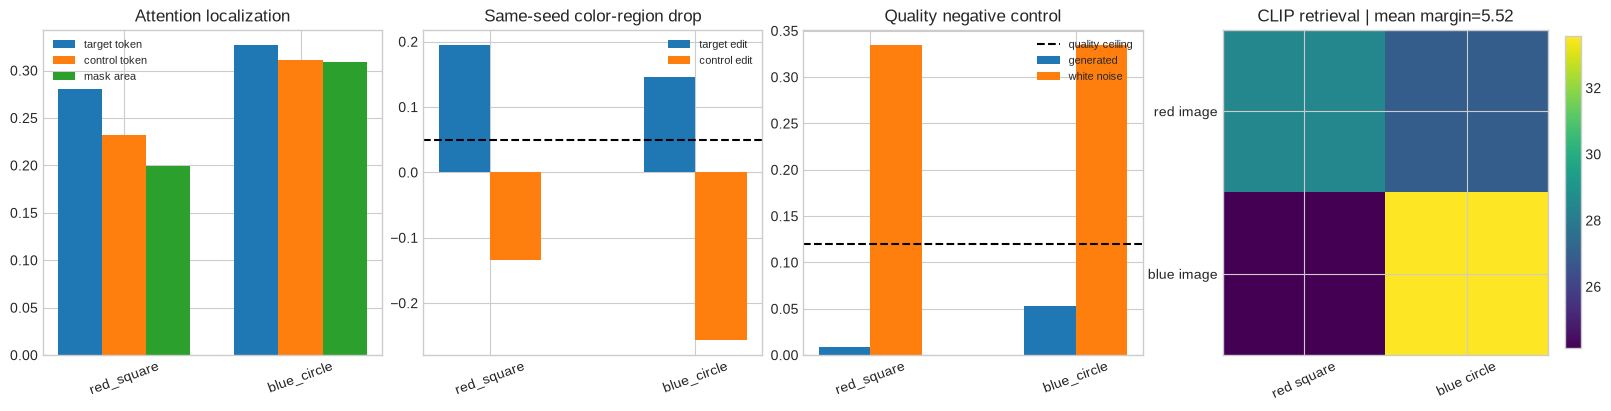

In [19]:
metrics_rows = []
for report in signature_result["case_reports"]:
    metrics_rows.append(
        {
            "case": report["case_id"],
            "target attention": report["target_region_mass"],
            "control attention": report["control_region_mass"],
            "mask fraction": report["mask_fraction"],
            "target edit drop": report["target_drop"],
            "control edit drop": report["random_control_drop"],
            "real high frequency": report["high_frequency_energy"],
            "noise high frequency": report["white_noise_high_frequency_energy"],
        }
    )
metrics_table = pd.DataFrame(metrics_rows)
display(metrics_table.style.format({c: "{:.3f}" for c in metrics_table.columns if c != "case"}))

fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)
x = np.arange(len(metrics_table)); width = 0.25
axes[0].bar(x-width, metrics_table["target attention"], width, label="target token")
axes[0].bar(x, metrics_table["control attention"], width, label="control token")
axes[0].bar(x+width, metrics_table["mask fraction"], width, label="mask area")
axes[0].set_title("Attention localization")
axes[0].legend(fontsize=8)
axes[1].bar(x-width/2, metrics_table["target edit drop"], width, label="target edit")
axes[1].bar(x+width/2, metrics_table["control edit drop"], width, label="control edit")
axes[1].axhline(0.05, color="black", linestyle="--")
axes[1].set_title("Same-seed color-region drop")
axes[1].legend(fontsize=8)
axes[2].bar(x-width/2, metrics_table["real high frequency"], width, label="generated")
axes[2].bar(x+width/2, metrics_table["noise high frequency"], width, label="white noise")
axes[2].axhline(0.12, color="black", linestyle="--", label="quality ceiling")
axes[2].set_title("Quality negative control")
axes[2].legend(fontsize=8)
clip_logits = np.array(signature_result["clip_logits"])
im = axes[3].imshow(clip_logits, cmap="viridis")
axes[3].set_xticks([0,1], ["red square", "blue circle"], rotation=25)
axes[3].set_yticks([0,1], ["red image", "blue image"])
axes[3].set_title(f"CLIP retrieval | mean margin={signature_result['clip_mean_positive_margin']:.2f}")
fig.colorbar(im, ax=axes[3], fraction=0.046)
for ax in axes[:3]:
    ax.set_xticks(x, metrics_table["case"], rotation=20)
evidence_path = assets_dir / "diffusion_image_generation_evidence_metrics.png"
fig.savefig(evidence_path, dpi=180, bbox_inches="tight")
plt.show()

![Expected SD1.5 evidence metrics](../../../chapter13_image_generation_interpretability/exercises/part1_diffusion_cross_attention/media/diffusion_image_generation_evidence_metrics.png)

<details>
<summary>Expected metrics</summary>

- target-control attention gap: at least `0.0147` in both cases;
- target-token color-region drop: at least `0.1507`;
- control-token drop: at most `-0.1346` (the target color increases rather than disappears);
- generated-image high-frequency energy: at most `0.0526`;
- white-noise high-frequency energy: about `0.334`;
- CLIP image-to-text and text-to-image retrieval: `1.0 / 1.0`;
- CLIP mean positive margin: about `5.90`.

</details>

## Try It Yourself

The next cell uses the real maps and images already generated. Change the case, inspect target versus control attention, shift the preregistered region mask, or swap the displayed
counterfactual. A convincing interpretation should collapse under the wrong token group or a badly shifted mask.

For the unchanged play values, forecast how shifting the region affects target/control mass. Then predict one changed setting.

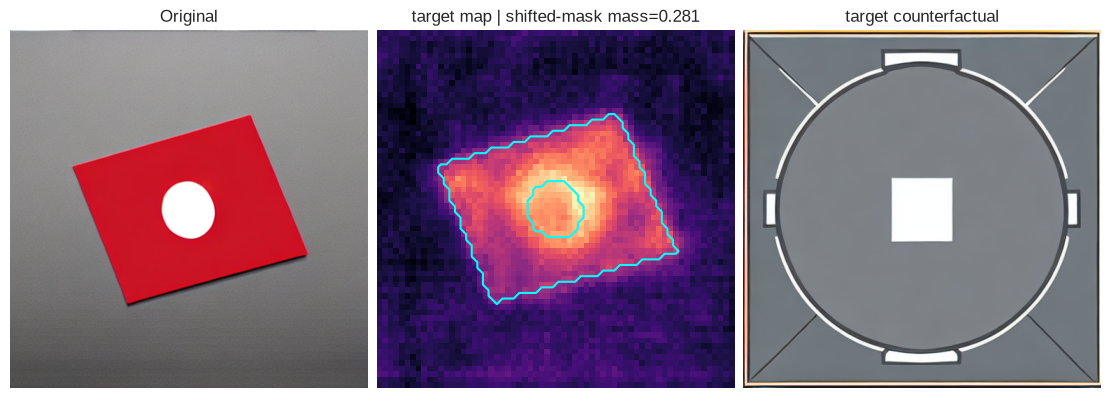

AttentionRegionReport(region_mass=0.28088125586509705, off_region_mass=0.719118744134903, region_selective=True)

In [20]:
# Try It Yourself: edit these values, then rerun this cell.
PLAY_CASE = "red_square"       # "red_square" or "blue_circle"
PLAY_MAP = "target"            # "target" or "control"
PLAY_MASK_SHIFT = (0, 0)        # (rows, columns) on the 64x64 map
PLAY_COUNTERFACTUAL = "target" # "target" or "control"
PLAY_MIN_REGION_MASS = 0.20

visual = next(v for v in signature_result["visual_cases"] if v["case_id"] == PLAY_CASE)
attention = visual[f"{PLAY_MAP}_attention"]
mask = t.roll(visual["region_mask"], shifts=PLAY_MASK_SHIFT, dims=(0, 1))
play_report = attention_region_report(
    attention, mask, min_region_mass=PLAY_MIN_REGION_MASS
)
edit_image = visual[f"{PLAY_COUNTERFACTUAL}_ablated_image"]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), constrained_layout=True)
axes[0].imshow(visual["original_image"]); axes[0].set_title("Original")
axes[1].imshow(attention, cmap="magma"); axes[1].contour(mask, colors="cyan")
axes[1].set_title(f"{PLAY_MAP} map | shifted-mask mass={play_report.region_mass:.3f}")
axes[2].imshow(edit_image); axes[2].set_title(f"{PLAY_COUNTERFACTUAL} counterfactual")
for ax in axes: ax.axis("off")
plt.show()
play_report

# ☆ Bonus

## Bonus: Hunt an Anomaly

Find a setting where the visual impression and a metric disagree. Useful searches include:

- shift the mask until a diffuse map appears selective;
- compare target and control attention with identical color scales;
- inspect why the control edit increases the measured target-color area;
- tighten the attention-gap or image-quality threshold until one case fails;
- rerun a benign shape prompt with a new fixed seed and check whether the claim survives.

Write down whether the failure is in region definition, attention localization, intervention specificity, image quality, or external semantic scoring.

## Limitations and Claim Boundary

Supported: two pinned benign SD1.5 prompts, real fp16 generation, captured cross-attention, independently defined color masks, same-seed target/control prompt edits, CLIP
retrieval, image-quality metrics, white-noise rejection, and measured CUDA VRAM.

Not supported: a full DAAM replication, denoising-step activation patching, a discovered internal circuit, latent steering, SDXL, video diffusion, autoregressive image tokens,
multi-object scenes, human perceptual evaluation, or broad claims about all prompts. Exercises 2 and 3 teach the contracts those future experiments must satisfy; they are not
counted as real-model evidence here.

## Verification Appendix

The live figures are the lesson. The committed report is a separately regenerated release artifact which protects the pinned checkpoint, thresholds, CUDA path, and VRAM budget.

In [21]:
def run_smoke_test(cpu: bool = True) -> dict:
    _ = cpu
    return {
        "attention_region": attention_region_report(
            t.tensor([[0.1, 0.1], [0.2, 0.6]]),
            t.tensor([[False, False], [False, True]]),
            min_region_mass=0.5,
        ).__dict__,
        "denoising_circuit": denoising_circuit_report(
            baseline_loss=0.2, ablated_loss=0.7, random_control_loss=0.35,
            min_loss_increase=0.3, min_control_gap=0.2,
        ).__dict__,
        "latent_direction": latent_direction_effect_report(
            t.tensor([0.1, 0.2]), t.tensor([0.7, 0.8]), t.tensor([0.25, 0.15]),
            expected_direction="increase", min_effect=0.5, min_random_margin=0.2,
        ).__dict__,
        "prompt_region": prompt_region_causal_report(
            original_region_score=0.85, ablated_region_score=0.25,
            control_region_score=0.7, min_target_drop=0.4, min_control_margin=0.2,
        ).__dict__,
        "shuffled_region_control": reference.shuffled_region_control_smoke_test(),
    }


def run_gpu_test(max_vram_gb: float = 24.0) -> dict:
    if signature_result["peak_vram_gb"] > max_vram_gb:
        raise RuntimeError("live SD1.5 result exceeded the requested VRAM budget")
    return signature_result


def run_full_experiment(max_vram_gb: float = 24.0) -> dict:
    return run_gpu_test(max_vram_gb=max_vram_gb)


verification_report = json.loads((section_dir / "verification_report.json").read_text())
tests.test_notebook_contract(run_smoke_test)
tests.test_committed_gpu_report_requires_sd15_strict_controls(verification_report)
if "signature_result" in globals():
    assert run_gpu_test()["preflight_passed"], (
        "The learner-visible SD1.5 experiment should pass every preregistered gate."
    )
    print("Live SD1.5 evidence and committed CUDA report both passed.")
else:
    print("CPU notebook checks passed; run the tagged live cells on CUDA for the signature result.")

All tests in `test_notebook_contract` passed!
All tests in `test_committed_gpu_report_requires_sd15_strict_controls` passed!
Live SD1.5 evidence and committed CUDA report both passed.


<details>
<summary>Expected output</summary>

```text
All tests in `test_notebook_contract` passed!
All tests in `test_committed_gpu_report_requires_sd15_strict_controls` passed!
Live SD1.5 evidence and committed CUDA report both passed.
```

</details>